# NB02d — Fine-tuning Grounding DINO untuk domain CCTV

## Tujuan dan batas kerja

Notebook ini menyesuaikan **Grounding DINO-Tiny** ke tampilan kendaraan dan pantulan pada CCTV proyek, lalu
membuat **proposal bbox tiga kelas** (`Mobil`, `Motor`, `PantulanCahaya`) untuk frame tambahan. Hasil model tetap proposal. Setiap frame
dan bbox harus diperiksa/dikoreksi manusia di NB02b sebelum masuk label supervised YOLO dan CNN.

NB02d memakai anotasi train yang sudah direview untuk update bobot dan validation untuk memantau
overfitting/memilih checkpoint. Metadata test hanya dipakai untuk memeriksa jumlah dan mencegah
overlap; gambar serta bbox test tidak masuk ke loss, training, atau pembuatan proposal. GT test
NB02c tetap dibekukan untuk evaluasi final.

## Target ukuran dataset berlabel

Test dikunci pada **254 frame**. Agar split mendekati 65/15/20 berdasarkan jumlah frame, total
akhir ditetapkan 1.270 frame: **826 train, 190 validation, 254 test** (65,04% / 14,96% / 20%).
Data aktif sekarang berisi 195 train, 79 validation, dan 254 test; sehingga NB02d menyiapkan
proposal untuk **631 train + 111 validation = 742 frame tambahan**. Persentase final baru tercapai
setelah seluruh proposal ditinjau dan diekspor sebagai anotasi reviewed.

## Aliran kerja

1. Validasi pemisahan kamera, jumlah GT, dan ROI aktif.
2. Fine-tune Grounding DINO hanya dengan frame train berlabel manual/edit.
3. Gunakan validation untuk memilih checkpoint terbaik; tidak ada update bobot dari validation.
4. Ambil frame tambahan hanya dari kamera train/validation, dengan jarak sampling minimum.
5. Simpan crop ROI dan proposal `Mobil`/`Motor`/`PantulanCahaya` ke `output/nb02d/proposal_manifest.json`.
6. Buka NB02b untuk review semua frame tambahan. Koreksi bbox, tandai PantulanCahaya secara eksplisit,
   dan tandai frame kosong setelah diperiksa. Jangan menerima pseudo-label tanpa pemeriksaan.
7. Pastikan ekspor akhir NB02b berisi 826/190 frame; lalu jalankan NB03–NB06.

FM memiliki tiga target deteksi: `Mobil`, `Motor`, dan `PantulanCahaya`. CNN NB04b juga dilatih
dengan label `Standar`, `TidakStandar`, dan `PantulanCahaya`. Pantulan tetap dikeluarkan sebelum
ByteTrack, overlay, dan counting. FM tidak memprediksi kondisi Standar/TidakStandar; label kondisi
kendaraan tetap berasal dari review manusia dan CNN.

## Catatan teknis

Implementasi memakai loss supervised Grounding DINO yang tersedia di Transformers; repository
resmi IDEA-Research menjelaskan bobot/model dan inferensi, sedangkan contoh fine-tuning dataset
kustom yang terdokumentasi tersedia pada MMDetection. Training dapat memakan waktu dan memori besar;
GPU CUDA disarankan. Jika training tidak stabil/kehabisan memori, kecilkan batch/epoch atau gunakan
GPU yang lebih besar. Jangan mengurangi/menyentuh GT test untuk mengatasi keterbatasan tersebut.


In [1]:
from collections import Counter, defaultdict
from pathlib import Path
import csv
import hashlib
import json
import math
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor

from pipeline_common import (
    SPLIT_NAME_BY_CAMERA,
    TRAINING_CLASS_NAMES,
    build_roi_crop,
    load_roi_config,
    training_class_name,
)

ROOT = Path(os.environ.get("RISET_PROJECT_ROOT", Path.cwd())).resolve()
if ROOT.name not in {"NewStyle", "Riset-HampirMatang"}:
    raise RuntimeError(
        "Jalankan notebook dari root proyek atau set RISET_PROJECT_ROOT."
    )
OUTPUT = ROOT / "output"
ANNOTATION_ROOT = OUTPUT / "annotation"
GT_ROOT = OUTPUT / "ground_truth"
NB02D_ROOT = OUTPUT / "nb02d"
IMAGE_DIR = NB02D_ROOT / "crops"
CHECKPOINT_DIR = NB02D_ROOT / "checkpoints" / "best"
HISTORY_PATH = NB02D_ROOT / "training_history.csv"
PROPOSAL_PATH = NB02D_ROOT / "proposal_manifest.json"
for directory in (NB02D_ROOT, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

TRAIN_MANIFEST_PATH = ANNOTATION_ROOT / "sample_manifest.json"
TRAIN_STORE_PATH = ANNOTATION_ROOT / "annotations.json"
TEST_MANIFEST_PATH = GT_ROOT / "sample_manifest.json"
TEST_STORE_PATH = GT_ROOT / "annotations.json"
FRAMES_MANIFEST_PATH = OUTPUT / "manifests" / "frames_manifest.csv"
ROI_CONFIG = load_roi_config(OUTPUT / "roi")
ROI_SIGNATURE = hashlib.sha256(
    json.dumps(ROI_CONFIG, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()

MODEL_ID = "IDEA-Research/grounding-dino-tiny"
PROMPT = "car. motorcycle. light reflection."
TARGETS = {"train": 826, "val": 190, "test": 254}
EXPECTED_CURRENT = {"train": 195, "val": 79, "test": 254}
MIN_FRAME_GAP = 30
RANDOM_SEED = 20261113
EPOCHS = int(os.environ.get("NB02D_EPOCHS", "8"))
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
BOX_THRESHOLD = 0.25
TEXT_THRESHOLD = 0.20
NMS_IOU_THRESHOLD = 0.60
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

display(
    Markdown(
        f"**NB02d siap** · device: `{DEVICE}` · model: `{MODEL_ID}` · "
        f"frame proposal tambahan: {TARGETS['train'] - EXPECTED_CURRENT['train']} train + "
        f"{TARGETS['val'] - EXPECTED_CURRENT['val']} validation."
    )
)
if DEVICE == "cpu":
    display(
        Markdown(
            "> CPU terdeteksi. Fine-tuning Grounding DINO dapat berjalan sangat lambat; GPU CUDA disarankan."
        )
    )

**NB02d siap** · device: `cpu` · model: `IDEA-Research/grounding-dino-tiny` · frame proposal tambahan: 631 train + 111 validation.

> CPU terdeteksi. Fine-tuning Grounding DINO dapat berjalan sangat lambat; GPU CUDA disarankan.

In [2]:
def read_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Artefak wajib tidak ditemukan: {path}")
    return json.loads(path.read_text(encoding="utf-8"))


train_manifest = read_json(TRAIN_MANIFEST_PATH)
train_store = read_json(TRAIN_STORE_PATH)
test_manifest = read_json(TEST_MANIFEST_PATH)
test_store = read_json(TEST_STORE_PATH)


def reviewed_records(
    manifest: dict, store: dict, expected_split: str | None = None
) -> list[dict]:
    records = []
    for record in manifest.get("frames", []):
        split = record.get("split", SPLIT_NAME_BY_CAMERA.get(record["camera_id"]))
        if expected_split is not None and split != expected_split:
            continue
        entry = store.get("frames", {}).get(record["frame_stem"], {})
        if entry.get("reviewed"):
            records.append({**record, "split": split, "annotation": entry})
    return records


reviewed_train = reviewed_records(train_manifest, train_store, "train")
reviewed_val = reviewed_records(train_manifest, train_store, "val")
reviewed_test = reviewed_records(test_manifest, test_store, "test")
actual_counts = {
    "train": len(reviewed_train),
    "val": len(reviewed_val),
    "test": len(reviewed_test),
}
if actual_counts != EXPECTED_CURRENT:
    raise ValueError(
        f"Jumlah label aktif berubah dari baseline yang direncanakan: {actual_counts}; "
        f"expected {EXPECTED_CURRENT}. Hitung ulang TARGETS sebelum melanjutkan."
    )
train_val_stems = {r["frame_stem"] for r in reviewed_train + reviewed_val}
test_stems = {r["frame_stem"] for r in reviewed_test}
if train_val_stems & test_stems:
    raise ValueError(
        "Kebocoran frame: ada frame NB02c test yang juga muncul di anotasi train/val."
    )

for record in reviewed_train + reviewed_val:
    image_path = Path(record["image_path"])
    if not image_path.exists():
        raise FileNotFoundError(f"Crop berlabel tidak ditemukan: {image_path}")
    if SPLIT_NAME_BY_CAMERA.get(record["camera_id"]) != record["split"]:
        raise ValueError(f"Split kamera berubah untuk {record['frame_stem']}.")

split_rows = []
for split_name in ("train", "val", "test"):
    split_rows.append(
        {
            "Split": split_name,
            "Frame reviewed sekarang": actual_counts[split_name],
            "Target akhir": TARGETS[split_name],
            "Proposal baru": max(0, TARGETS[split_name] - actual_counts[split_name]),
        }
    )
display(pd.DataFrame(split_rows))
display(
    Markdown(
        f"**GT test tetap:** {len(reviewed_test)} frame reviewed. Notebook hanya memakai "
        "frame train untuk update bobot dan frame validation untuk pemantauan."
    )
)


class VehicleFrameDataset(Dataset):
    def __init__(self, records: list[dict]):
        self.records = records

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, index: int) -> dict:
        record = self.records[index]
        image = Image.open(record["image_path"]).convert("RGB")
        width, height = image.size
        annotations = []
        for box_entry in record["annotation"].get("boxes", []):
            if box_entry.get("deleted"):
                continue
            class_name = training_class_name(box_entry.get("class_name", ""))
            if class_name not in TRAINING_CLASS_NAMES:
                continue
            x1, y1, x2, y2 = [float(v) for v in box_entry["box"]]
            if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
                raise ValueError(
                    f"BBox manual keluar batas untuk {record['frame_stem']}: {box_entry['box']}"
                )
            annotations.append(
                {
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "category_id": TRAINING_CLASS_NAMES.index(class_name),
                    "area": (x2 - x1) * (y2 - y1),
                    "iscrowd": 0,
                }
            )
        target = {"image_id": index, "annotations": annotations}
        return {"image": image, "target": target}


def collate_grounding_dino(batch: list[dict]) -> dict:
    # In transformers 5.x, the combined GroundingDinoProcessor ignores
    # `annotations` as an unknown tokenizer argument. Route COCO targets through
    # the image processor so boxes are resized/padded and returned as `labels`.
    image_inputs = processor.image_processor(
        images=[item["image"] for item in batch],
        annotations=[item["target"] for item in batch],
        return_tensors="pt",
    )
    labels = [
        {
            key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
            for key, value in item.items()
        }
        for item in image_inputs.pop("labels")
    ]
    text_inputs = processor.tokenizer(
        text=[PROMPT] * len(batch),
        padding=True,
        return_tensors="pt",
    )
    encoded = {**image_inputs, **text_inputs}
    return {
        "inputs": {key: value.to(DEVICE) for key, value in encoded.items()},
        "labels": labels,
    }


train_dataset = VehicleFrameDataset(reviewed_train)
val_dataset = VehicleFrameDataset(reviewed_val)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_grounding_dino,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_grounding_dino
)
train_vehicle_boxes = sum(
    len(train_dataset[i]["target"]["annotations"]) for i in range(len(train_dataset))
)
val_vehicle_boxes = sum(
    len(val_dataset[i]["target"]["annotations"]) for i in range(len(val_dataset))
)
display(
    Markdown(
        f"Data fine-tune: **{len(train_dataset)} frame train / {train_vehicle_boxes} bbox kendaraan**. "
        f"Validation: **{len(val_dataset)} frame / {val_vehicle_boxes} bbox objek**. "
        "PantulanCahaya menjadi target eksplisit kelas ketiga."
    )
)

,Split,Frame reviewed sekarang,Target akhir,Proposal baru
0,train,195,826,631
1,val,79,190,111
2,test,254,254,0


**GT test tetap:** 254 frame reviewed. Notebook hanya memakai frame train untuk update bobot dan frame validation untuk pemantauan.

Data fine-tune: **195 frame train / 2038 bbox kendaraan**. Validation: **79 frame / 1202 bbox objek**. PantulanCahaya menjadi target eksplisit kelas ketiga.

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

epoch 01/8 · train loss 13515.5873 · val loss 7421.8420


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 02/8 · train loss 11668.9881 · val loss 6326.6234


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 03/8 · train loss 9855.6570 · val loss 5291.3567


... (7 outputs left out)

epoch 07/8 · train loss 4065.6624 · val loss 2047.8197


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 08/8 · train loss 3063.7443 · val loss 1525.4967


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

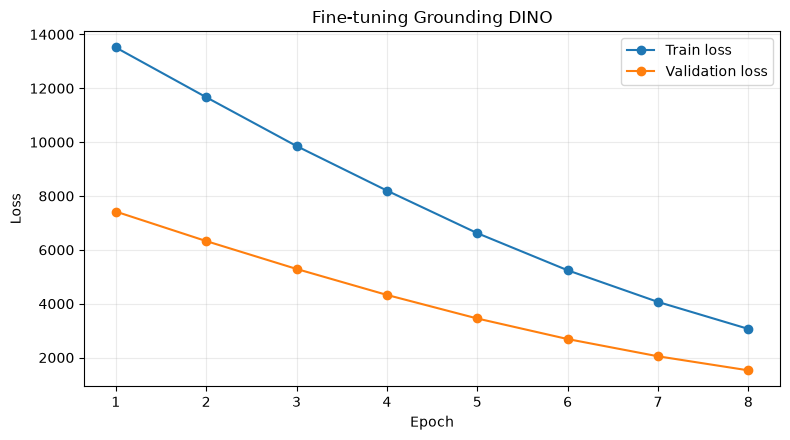

Checkpoint terbaik: epoch **8** · validation loss **1525.4967** · `D:\Jere\NewStyle\output\nb02d\checkpoints\best`. Metrik ini memantau proposal detector; bukan evaluasi final test.

In [3]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID).to(DEVICE)

# Bekukan encoder teks agar prompt bahasa tetap stabil; update bobot visual/detection Grounding DINO.
for parameter in model.model.text_backbone.parameters():
    parameter.requires_grad = False
trainable_parameters = [
    parameter for parameter in model.parameters() if parameter.requires_grad
]
if not trainable_parameters:
    raise RuntimeError("Tidak ada parameter trainable pada model Grounding DINO.")
optimizer = torch.optim.AdamW(
    trainable_parameters, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")


def move_batch(batch: dict) -> tuple[dict, list[dict]]:
    return batch["inputs"], batch["labels"]


def run_epoch(loader: DataLoader, training: bool) -> float:
    model.train(training)
    loss_total = 0.0
    item_total = 0
    if training:
        optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(loader, start=1):
        inputs, labels = move_batch(batch)
        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"
            ):
                output = model(**inputs, labels=labels)
                loss = output.loss
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Loss tidak finite pada step {step}: {loss.item()}"
                )
            if training:
                scaler.scale(loss / GRAD_ACCUM_STEPS).backward()
                should_step = step % GRAD_ACCUM_STEPS == 0 or step == len(loader)
                if should_step:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(trainable_parameters, 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
        loss_total += float(loss.detach().cpu())
        item_total += 1
    return loss_total / max(item_total, 1)


history_rows = []
best_val_loss = float("inf")
best_epoch = None
stale_epochs = 0
EARLY_STOPPING_PATIENCE = 2
for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)
    history_rows.append(
        {"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss}
    )
    print(
        f"epoch {epoch:02d}/{EPOCHS} · train loss {train_loss:.4f} · val loss {val_loss:.4f}"
    )
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        stale_epochs = 0
        CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
        model.save_pretrained(CHECKPOINT_DIR)
        processor.save_pretrained(CHECKPOINT_DIR)
    else:
        stale_epochs += 1
        if stale_epochs >= EARLY_STOPPING_PATIENCE:
            print("Early stopping: validation loss tidak membaik.")
            break

history_frame = pd.DataFrame(history_rows)
HISTORY_PATH.parent.mkdir(parents=True, exist_ok=True)
history_frame.to_csv(HISTORY_PATH, index=False)
figure, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(
    history_frame["epoch"], history_frame["train_loss"], marker="o", label="Train loss"
)
axis.plot(
    history_frame["epoch"],
    history_frame["val_loss"],
    marker="o",
    label="Validation loss",
)
axis.set(title="Fine-tuning Grounding DINO", xlabel="Epoch", ylabel="Loss")
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
figure.savefig(NB02D_ROOT / "training_curves.png", dpi=140)
plt.show()
if best_epoch is None:
    raise RuntimeError("Checkpoint fine-tuned tidak berhasil disimpan.")
display(
    Markdown(
        f"Checkpoint terbaik: epoch **{best_epoch}** · validation loss **{best_val_loss:.4f}** · "
        f"`{CHECKPOINT_DIR}`. Metrik ini memantau proposal detector; bukan evaluasi final test."
    )
)

In [5]:
frames_rows = []
with FRAMES_MANIFEST_PATH.open(encoding="utf-8-sig", newline="") as source_file:
    for row in csv.DictReader(source_file):
        video_stem = Path(row["video_path"]).stem
        camera_id = video_stem.split("_")[1]
        split = SPLIT_NAME_BY_CAMERA.get(camera_id)
        if split not in {"train", "val"}:
            continue  # Test tidak dibuat proposal dan tidak dibaca sebagai input.
        frame_stem = f"{video_stem}_{Path(row['frame_path']).stem}"
        frames_rows.append(
            {
                "frame_stem": frame_stem,
                "video_stem": video_stem,
                "camera_id": camera_id,
                "split": split,
                "frame_path": row["frame_path"],
            }
        )

existing_records = reviewed_train + reviewed_val
existing_stems = {record["frame_stem"] for record in existing_records}
existing_by_camera = defaultdict(list)
for record in existing_records:
    frame_number = int(Path(record["frame_path"]).stem.split("_")[-1])
    existing_by_camera[record["camera_id"]].append(frame_number)

needed_by_split = {
    split: TARGETS[split] - EXPECTED_CURRENT[split] for split in ("train", "val")
}
if any(value < 0 for value in needed_by_split.values()):
    raise ValueError(f"Label aktif sudah melebihi target: {needed_by_split}")
candidate_by_camera = defaultdict(list)
for record in frames_rows:
    if record["frame_stem"] in existing_stems:
        continue
    candidate_by_camera[record["camera_id"]].append(record)


def allocate_camera_quota(camera_counts: dict[str, int], total: int) -> dict[str, int]:
    capacity = sum(camera_counts.values())
    if total > capacity:
        raise ValueError(
            f"Kapasitas kamera {capacity} lebih kecil dari kebutuhan {total}."
        )
    exact = {
        camera: total * count / capacity for camera, count in camera_counts.items()
    }
    quotas = {camera: int(value) for camera, value in exact.items()}
    remainder = total - sum(quotas.values())
    for camera in sorted(
        camera_counts, key=lambda key: (-(exact[key] - quotas[key]), key)
    )[:remainder]:
        quotas[camera] += 1
    return quotas


def build_spaced_pool(records: list[dict], already_selected: list[int]) -> list[dict]:
    """Build a maximum-size set of candidates honoring the minimum frame gap."""
    ordered = sorted(
        records,
        key=lambda record: (
            record["video_stem"],
            int(Path(record["frame_path"]).stem.split("_")[-1]),
        ),
    )
    selected = []
    blocked = list(already_selected)
    last_video = None
    last_selected_number = None
    for record in ordered:
        video_stem = record["video_stem"]
        number = int(Path(record["frame_path"]).stem.split("_")[-1])
        if video_stem != last_video:
            last_video = video_stem
            last_selected_number = None
        if any(abs(number - prior) < MIN_FRAME_GAP for prior in already_selected):
            continue
        if (
            last_selected_number is not None
            and number - last_selected_number < MIN_FRAME_GAP
        ):
            continue
        selected.append(record)
        last_selected_number = number
    return selected


def choose_spaced(records: list[dict], count: int, seed: int) -> list[dict]:
    """Choose an exact, temporally distributed subset from a feasible spaced pool."""
    if count < 0 or count > len(records):
        raise ValueError(
            f"Kapasitas sampling tidak cukup: perlu {count}, kapasitas layak {len(records)} "
            f"pada jarak minimum {MIN_FRAME_GAP} frame."
        )
    if count == 0:
        return []
    # The input pool is already spaced. Select one random candidate from each
    # temporal stratum so a feasible quota cannot fail due to random greedy order.
    rng = random.Random(seed)
    strata = np.array_split(np.arange(len(records)), count)
    selected_indices = [rng.choice(stratum.tolist()) for stratum in strata]
    return [records[index] for index in selected_indices]


selected_records = []
for split_name, needed in needed_by_split.items():
    camera_ids = sorted(
        camera_id
        for camera_id in candidate_by_camera
        if SPLIT_NAME_BY_CAMERA[camera_id] == split_name
    )
    spaced_pool_by_camera = {
        camera_id: build_spaced_pool(
            candidate_by_camera[camera_id], existing_by_camera[camera_id]
        )
        for camera_id in camera_ids
    }
    capacity_by_camera = {
        camera_id: len(spaced_pool_by_camera[camera_id]) for camera_id in camera_ids
    }
    camera_quotas = allocate_camera_quota(capacity_by_camera, needed)
    for camera_id, quota in camera_quotas.items():
        chosen = choose_spaced(
            spaced_pool_by_camera[camera_id],
            quota,
            RANDOM_SEED + sum(ord(char) for char in camera_id),
        )
        selected_records.extend(chosen)

if len(selected_records) != sum(needed_by_split.values()):
    raise AssertionError("Jumlah frame proposal tidak sesuai target split.")
proposal_model = (
    AutoModelForZeroShotObjectDetection.from_pretrained(CHECKPOINT_DIR)
    .to(DEVICE)
    .eval()
)
proposal_processor = AutoProcessor.from_pretrained(CHECKPOINT_DIR)


def class_aware_nms(detections: list[dict]) -> list[dict]:
    kept = []
    for vehicle_type in TRAINING_CLASS_NAMES:
        class_rows = [row for row in detections if row["vehicle_type"] == vehicle_type]
        class_rows.sort(key=lambda row: row["score"], reverse=True)
        accepted = []
        for row in class_rows:
            x1, y1, x2, y2 = row["box"]
            area = max(0.0, x2 - x1) * max(0.0, y2 - y1)
            overlaps = False
            for prior in accepted:
                px1, py1, px2, py2 = prior["box"]
                intersection = max(0.0, min(x2, px2) - max(x1, px1)) * max(
                    0.0, min(y2, py2) - max(y1, py1)
                )
                prior_area = max(0.0, px2 - px1) * max(0.0, py2 - py1)
                union = area + prior_area - intersection
                if union > 0 and intersection / union > NMS_IOU_THRESHOLD:
                    overlaps = True
                    break
            if not overlaps:
                accepted.append(row)
        kept.extend(accepted)
    return kept


proposal_rows = []
for position, record in enumerate(selected_records, start=1):
    source_path = ROOT / record["frame_path"]
    if not source_path.exists():
        raise FileNotFoundError(f"Frame sumber hilang: {source_path}")
    with Image.open(source_path) as source_image:
        roi_image, _, _, _ = build_roi_crop(
            source_image.convert("RGB"), ROI_CONFIG.get(record["camera_id"])
        )
    image_path = IMAGE_DIR / f"{record['frame_stem']}.png"
    roi_image.save(image_path)
    width, height = roi_image.size
    inputs = proposal_processor(images=roi_image, text=PROMPT, return_tensors="pt").to(
        DEVICE
    )
    with torch.inference_mode():
        outputs = proposal_model(**inputs)
    result = proposal_processor.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=BOX_THRESHOLD,
        text_threshold=TEXT_THRESHOLD,
        target_sizes=[(height, width)],
    )[0]
    detections = []
    for box, score, phrase in zip(
        result["boxes"], result["scores"], result["text_labels"]
    ):
        phrase = str(phrase).lower()
        vehicle_type = (
            "PantulanCahaya"
            if "reflection" in phrase
            else "Motor"
            if "motorcycle" in phrase
            else "Mobil"
            if "car" in phrase
            else None
        )
        if vehicle_type not in TRAINING_CLASS_NAMES:
            continue
        x1, y1, x2, y2 = [float(value) for value in box.detach().cpu().tolist()]
        x1, x2 = sorted((max(0.0, min(width, x1)), max(0.0, min(width, x2))))
        y1, y2 = sorted((max(0.0, min(height, y1)), max(0.0, min(height, y2))))
        if x2 - x1 < 2 or y2 - y1 < 2:
            continue
        detections.append(
            {
                "box": [round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)],
                "score": round(float(score.detach().cpu()), 5),
                "vehicle_type": vehicle_type,
                "vehicle_vote": vehicle_type,
                "lamp_count": 0,
                "signals_agree": True,
                "proposal_model": "NB02d_GroundingDINO_finetuned",
            }
        )
    detections = class_aware_nms(detections)
    proposal_rows.append(
        {
            **record,
            "image_path": str(image_path),
            "image_width": width,
            "image_height": height,
            "detections": detections,
        }
    )
    if position % 25 == 0 or position == len(selected_records):
        print(f"proposal {position}/{len(selected_records)}")

proposal_summary = {
    "status": "complete",
    "model_id": MODEL_ID,
    "checkpoint_path": str(CHECKPOINT_DIR),
    "roi_signature": ROI_SIGNATURE,
    "random_seed": RANDOM_SEED,
    "min_frame_gap": MIN_FRAME_GAP,
    "thresholds": {
        "box": BOX_THRESHOLD,
        "text": TEXT_THRESHOLD,
        "class_nms_iou": NMS_IOU_THRESHOLD,
    },
    "current_reviewed_frames": EXPECTED_CURRENT,
    "target_frames": TARGETS,
    "new_proposal_frames": dict(needed_by_split),
    "proposal_boxes": sum(len(row["detections"]) for row in proposal_rows),
    "class_names": TRAINING_CLASS_NAMES,
    "human_review_required": True,
    "frames": proposal_rows,
}
PROPOSAL_PATH.write_text(
    json.dumps(proposal_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

proposal_counts = Counter(row["split"] for row in proposal_rows)
box_counts = Counter(
    detection["vehicle_type"]
    for row in proposal_rows
    for detection in row["detections"]
)
display(
    pd.DataFrame(
        [
            {
                "Split": split,
                "Frame proposal": proposal_counts[split],
                "BBox proposal": sum(
                    len(row["detections"])
                    for row in proposal_rows
                    if row["split"] == split
                ),
            }
            for split in ("train", "val")
        ]
    )
)
display(
    Markdown(
        f"Tersimpan **{len(proposal_rows)} frame / {proposal_summary['proposal_boxes']} bbox proposal** "
        f"ke `{PROPOSAL_PATH}`. Ini belum menjadi label final. Review semua item di NB02b sebelum ekspor."
    )
)

Loading weights:   0%|          | 0/980 [00:00<?, ?it/s]

proposal 25/742
proposal 50/742
proposal 75/742
proposal 100/742
proposal 125/742
proposal 150/742
proposal 175/742
proposal 200/742
proposal 225/742
proposal 250/742
proposal 275/742
proposal 300/742
proposal 325/742
proposal 350/742
proposal 375/742
proposal 400/742
proposal 425/742
proposal 450/742
proposal 475/742
proposal 500/742
proposal 525/742
proposal 550/742
proposal 575/742
proposal 600/742
proposal 625/742
proposal 650/742
proposal 675/742
proposal 700/742
proposal 725/742
proposal 742/742


,Split,Frame proposal,BBox proposal
0,train,631,11862
1,val,111,2993


Tersimpan **742 frame / 14855 bbox proposal** ke `D:\Jere\NewStyle\output\nb02d\proposal_manifest.json`. Ini belum menjadi label final. Review semua item di NB02b sebelum ekspor.

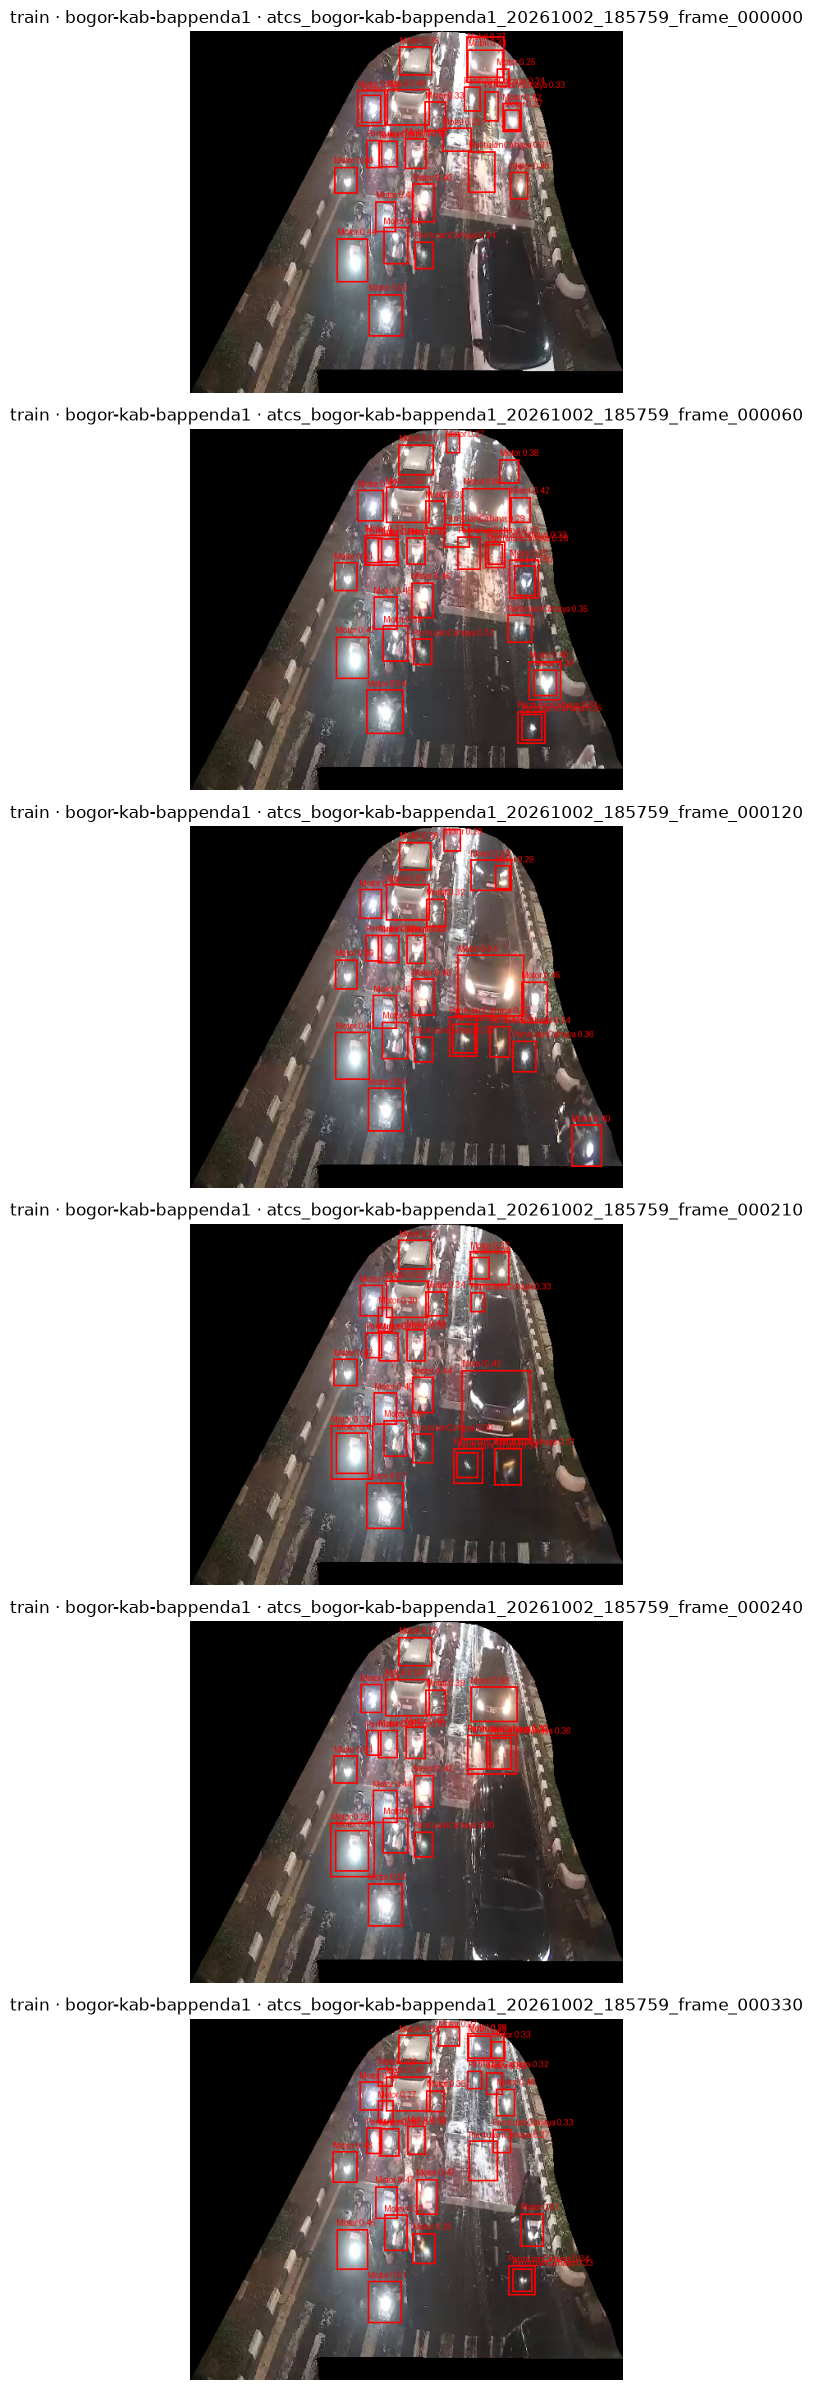

### Lanjutkan anotasi manual
1. Jalankan NB02b setelah NB02d selesai.
2. Review setiap bbox proposal, tambahkan objek yang terlewat, dan hapus false positive.
3. Beri label `PantulanCahaya` pada refleksi yang relevan; tandai frame kosong setelah benar-benar diperiksa.
4. Export NB02b dan pastikan ringkasan menunjukkan 826 train + 190 validation.
5. GT test 254 frame tetap terpisah dan tidak disentuh.

In [6]:
# Preview beberapa proposal untuk pemeriksaan cepat sebelum seluruh anotasi dibuka di NB02b.
preview_rows = [row for row in proposal_rows if row["detections"]][:6]
if not preview_rows:
    display(
        Markdown(
            "Tidak ada bbox proposal pada enam sampel pertama; frame tanpa proposal tetap wajib direview sebagai kemungkinan frame negatif."
        )
    )
else:
    figure, axes = plt.subplots(
        len(preview_rows), 1, figsize=(12, 4 * len(preview_rows))
    )
    axes = np.atleast_1d(axes)
    for axis, row in zip(axes, preview_rows):
        image = Image.open(row["image_path"]).convert("RGB")
        draw = ImageDraw.Draw(image)
        for detection in row["detections"]:
            draw.rectangle(detection["box"], outline="red", width=2)
            draw.text(
                (detection["box"][0], max(0, detection["box"][1] - 14)),
                f"{detection['vehicle_type']} {detection['score']:.2f}",
                fill="red",
            )
        axis.imshow(image)
        axis.set_title(f"{row['split']} · {row['camera_id']} · {row['frame_stem']}")
        axis.axis("off")
    figure.tight_layout()
    plt.show()

display(
    Markdown(
        "### Lanjutkan anotasi manual\n"
        "1. Jalankan NB02b setelah NB02d selesai.\n"
        "2. Review setiap bbox proposal, tambahkan objek yang terlewat, dan hapus false positive.\n"
        "3. Beri label `PantulanCahaya` pada refleksi yang relevan; tandai frame kosong setelah benar-benar diperiksa.\n"
        "4. Export NB02b dan pastikan ringkasan menunjukkan 826 train + 190 validation.\n"
        "5. GT test 254 frame tetap terpisah dan tidak disentuh."
    )
)